# Chapitre 10 - Exercices 10.6 à 10.11

Ce notebook traite six exercices sur les caches, l'observabilité, l'orchestration et les
retours utilisateurs (cours 2 à 4) :

- **10.6** : le seuil optimal d'un cache sémantique et sa robustesse (calcul + mini-lab) ;
- **10.7** : reproduire et corriger une fuite de données par le cache (mini-lab) ;
- **10.8** : régler une alerte CUSUM : fausses alertes contre délai de détection (calcul + simulation) ;
- **10.9** : chemin critique d'un pipeline et placement d'un garde-fou lent (calcul) ;
- **10.10** : apprendre un score de satisfaction implicite à partir des signaux (mini-lab) ;
- **10.11** : biais de position, puissance statistique et boucle de rétroaction (calcul + simulation).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from aie.plotting import set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, COLORS, annotate_bars
from aie import llm
from aie import ch10_architecture as A

set_style()
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
embed = lambda texts: llm.embed(texts, llm.EMBED_MULTI)

## Exercice 10.6 : Le seuil optimal d'un cache sémantique

**Énoncé.** (1) Avec les notations du cours 2 ($h$ taux de succès, $e$ taux d'erreur, $c$ coût
d'un appel, $c_{lk}$ coût de la recherche dans le cache, $c_{err}$ coût d'une mauvaise
réponse), donner la condition pour que le cache sémantique soit rentable. (2) Sur le flux
`A.CACHE_QUERIES`, calculer le seuil optimal $\tau^*$ pour $c_{err} \in \{0, 1, 2, 5, 10, 20\}$
(en unités de $c$, avec $c_{lk} = 0{,}02$). (3) Le taux de succès dépend de l'**ordre**
d'arrivée des requêtes : mesurer sa variabilité sur 200 ordres aléatoires au seuil 0,8.
(4) Que devient la rentabilité si seule une fraction $\rho$ du trafic réel ressemble à ce jeu
(le reste n'a jamais de paraphrase en cache) ?

**Rappels.** Section *Semantic caching* : le cache sémantique n'a de valeur que si le taux
de succès est élevé ; sa recherche vectorielle coûte à chaque requête et une erreur renvoie
la réponse à une autre question. Cours 2 : $\bar c = c_{lk} + (1-h)\,c + e\,c_{err}$.

**Solution.** (1) Le cache est rentable si $\bar c < c$, soit
$$h\,c > c_{lk} + e\,c_{err} :$$
l'économie des succès doit couvrir le coût fixe de la recherche **et** le coût des erreurs.

(2) On évalue $\bar c(\tau)$ sur une grille et on prend l'argmin (ci-dessous).

(4) Sur une fraction $1-\rho$ du trafic, aucune paraphrase n'existe : au mieux pas de succès
(et, pour un seuil bas, de faux succès). En première approximation $h \to \rho h$ et
$e \to \rho e + (1-\rho) e_0$, où $e_0$ est le taux de faux succès sur des requêtes sans
paraphrase. Avec $e_0 \approx 0$ (seuil assez haut), la condition devient
$\rho\,(h c - e\,c_{err}) > c_{lk}$ : il faut $\rho > c_{lk}/(h c - e c_{err})$.

In [2]:
cq = [q for q, _ in A.CACHE_QUERIES]; cg = np.array([g for _, g in A.CACHE_QUERIES])
Ec = embed(cq)
thr = np.linspace(0.5, 1.0, 51)
st = A.pairwise_cache_stats(Ec, cg, thr)
c, c_lk = 1.0, 0.02
rows = []
for c_err in [0, 1, 2, 5, 10, 20]:
    cost = c_lk + (1 - st["hit_rate"]) * c + st["err_rate"] * c_err
    j = int(np.argmin(cost))
    rows.append({"c_err": c_err, "tau*": thr[j], "h": st["hit_rate"][j], "e": st["err_rate"][j], "coût": cost[j],
                 "gain vs sans cache": 1 - cost[j] / c})
opt = pd.DataFrame(rows); opt.round(3)

,c_err,tau*,h,e,coût,gain vs sans cache
0,0,0.50,0.667,0.194,0.353,0.647
1,1,0.54,0.611,0.139,0.548,0.452
2,2,0.54,0.611,0.139,0.687,0.313
3,5,0.82,0.194,0.000,0.826,0.174
4,10,0.82,0.194,0.000,0.826,0.174
5,20,0.82,0.194,0.000,0.826,0.174


**Vérification** (3) : variabilité due à l'ordre, et (4) : rentabilité selon $\rho$.

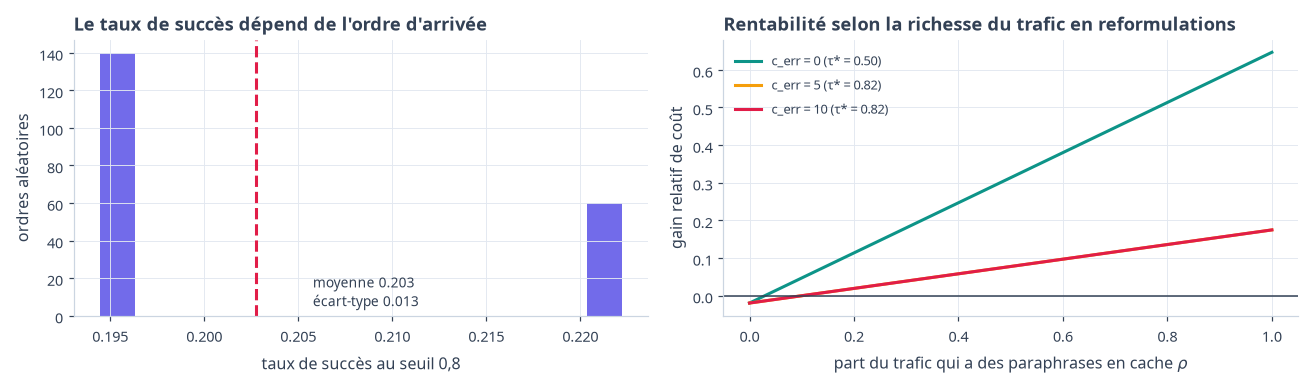

In [3]:
hits = []
for s in range(200):
    perm = np.random.default_rng(s).permutation(len(cq))
    hits.append(A.pairwise_cache_stats(Ec[perm], cg[perm], [0.8])["hit_rate"][0])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(hits, bins=15, color=INDIGO, alpha=0.8)
ax[0].axvline(np.mean(hits), color=ROSE, ls="--"); ax[0].text(np.mean(hits) + 0.003, 5, f"moyenne {np.mean(hits):.3f}\nécart-type {np.std(hits):.3f}", fontsize=9)
ax[0].set(xlabel="taux de succès au seuil 0,8", ylabel="ordres aléatoires", title="Le taux de succès dépend de l'ordre d'arrivée")
rhos = np.linspace(0, 1, 101)
for c_err, col in [(0, TEAL), (5, AMBER), (10, ROSE)]:
    r = opt[opt.c_err == c_err].iloc[0]
    ax[1].plot(rhos, 1 - (c_lk + (1 - rhos * r.h) * c + rhos * r.e * c_err) / c, color=col, label=f"c_err = {c_err} (τ* = {r['tau*']:.2f})")
ax[1].axhline(0, color=SLATE, lw=1)
ax[1].set(xlabel="part du trafic qui a des paraphrases en cache $\\rho$", ylabel="gain relatif de coût",
          title="Rentabilité selon la richesse du trafic en reformulations")
ax[1].legend(fontsize=8.5); plt.tight_layout(); plt.show()

Le seuil optimal **remonte** quand le coût d'une erreur augmente, et le gain fond. L'ordre
d'arrivée change le taux de succès de quelques points (sur 36 requêtes, chaque succès pèse
près de 3 %) : un réglage fait sur un petit échantillon est fragile. Enfin, quand le trafic
contient peu de reformulations ($\rho$ faible), le gain devient négatif : le coût fixe de la
recherche n'est plus couvert.

> **À retenir.** Cache sémantique rentable $\iff h\,c > c_{lk} + e\,c_{err}$ ; le seuil
> optimal croît avec le coût des erreurs, et tout dépend de la part réelle de reformulations.

## Exercice 10.7 : Reproduire et corriger une fuite de données par le cache

**Énoncé.** Le livre décrit une fuite : une question d'apparence générique (« quelle est la
politique de retour ? ») reçoit une réponse construite à partir du profil de l'utilisateur
(membre premium ou standard), la réponse est mise en cache puis servie à un autre
utilisateur. (1) Simuler 2 000 requêtes de 60 utilisateurs (deux segments) avec un cache
exact naïf et compter les réponses **fausses ou fuitées**. (2) Comparer trois corrections :
filtrer les requêtes personnelles (`A.is_cacheable`), inclure le segment dans la clé,
combiner les deux. (3) Mesurer pour chacune le taux de succès conservé.

**Rappels.** Section *Exact caching* (encadré) : une mise en cache mal maîtrisée peut causer
des fuites ; les requêtes spécifiques à un utilisateur ne doivent pas être mises en cache.
Cours 2 : `ExactCache.get(query, scope=...)` permet d'inclure un contexte dans la clé.

**Solution.** Trois familles de requêtes : **génériques** (même réponse pour tous),
**dépendantes du segment** (politique de retour, frais de livraison) et **personnelles**
(« où en est ma commande ? »). La réponse correcte dépend respectivement de rien, du
segment, de l'utilisateur. Une réponse servie par le cache est une **fuite** si elle a été
calculée pour un autre utilisateur et qu'elle diffère de la bonne réponse.

In [4]:
generic = ["Quels moyens de paiement acceptez-vous ?", "Où se trouve le magasin de Lyon ?", "Comment changer de mot de passe ?"]
segment_dep = ["Quelle est la politique de retour ?", "Combien coûte la livraison ?"]
personal = ["Où en est ma commande ?", "Quel est mon solde de points fidélité ?"]
users = {f"u{i}": ("premium" if i % 3 == 0 else "standard") for i in range(60)}

def true_answer(q, u):
    if q in generic:
        return f"réponse générique à « {q} »"
    if q in segment_dep:
        return f"réponse pour le segment {users[u]} à « {q} »"
    return f"réponse personnelle pour {u} à « {q} »"

def run(strategy, n=2000, seed=0):
    r = np.random.default_rng(seed)
    cache = A.ExactCache(capacity=10_000)
    leaks = wrong = hits = 0
    pool = generic * 3 + segment_dep * 2 + personal
    for _ in range(n):
        u = f"u{r.integers(60)}"; q = pool[r.integers(len(pool))]
        use = strategy != "sans cache" and (strategy in ("naïf", "segment dans la clé") or A.is_cacheable(q))
        scope = users[u] if strategy in ("segment dans la clé", "filtre + segment") else ""
        ans = cache.get(q, scope) if use else None
        hits += ans is not None
        if ans is None:
            ans = (true_answer(q, u), u)
            if use:
                cache.put(q, ans, scope)
        served, owner = ans
        if served != true_answer(q, u):
            wrong += 1
            leaks += owner != u and q in personal
    return {"stratégie": strategy, "taux de succès": hits / n,
            "réponses fausses": wrong, "dont données personnelles d'autrui": leaks}

res = pd.DataFrame([run(s) for s in ["naïf", "filtre is_cacheable", "segment dans la clé", "filtre + segment", "sans cache"]])
res

,stratégie,taux de succès,réponses fausses,dont données personnelles d'autrui
0,naïf,0.9965,510,250
1,filtre is_cacheable,0.8690,260,0
2,segment dans la clé,0.9930,244,244
3,filtre + segment,0.8665,0,0
4,sans cache,0.0000,0,0


**Vérification** graphique.

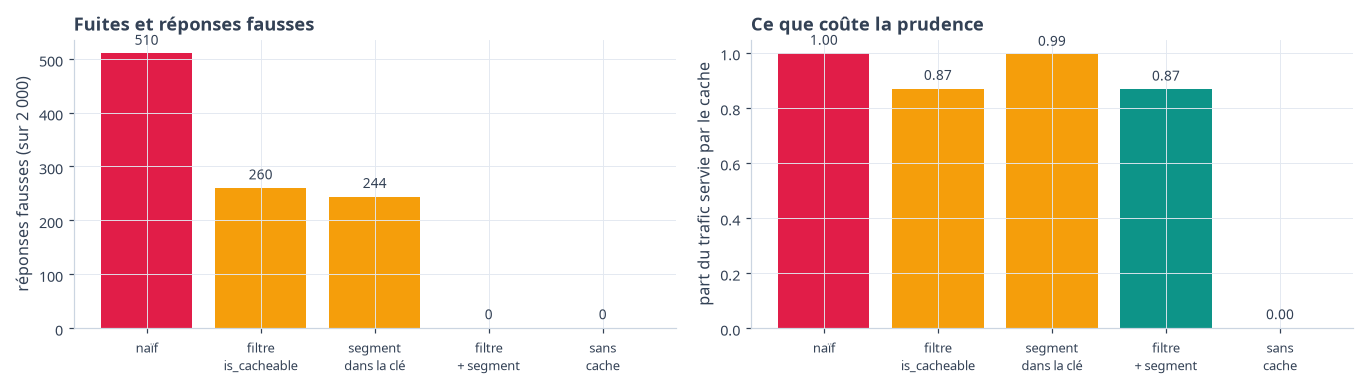

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.6))
cols = [ROSE, AMBER, AMBER, TEAL, GRAY]
ax[0].bar(range(len(res)), res["réponses fausses"], color=cols); annotate_bars(ax[0], "{:.0f}")
ax[0].set_xticks(range(len(res)), [s.replace(" ", "\n", 1) for s in res["stratégie"]], fontsize=8.5)
ax[0].set(ylabel="réponses fausses (sur 2 000)", title="Fuites et réponses fausses")
ax[1].bar(range(len(res)), res["taux de succès"], color=cols); annotate_bars(ax[1], "{:.2f}")
ax[1].set_xticks(range(len(res)), [s.replace(" ", "\n", 1) for s in res["stratégie"]], fontsize=8.5)
ax[1].set(ylabel="part du trafic servie par le cache", title="Ce que coûte la prudence")
plt.tight_layout(); plt.show()

Le cache naïf sert des centaines de réponses fausses, dont des données personnelles d'autres
clients. Le filtre `is_cacheable` supprime les fuites personnelles (« ma commande ») mais
laisse passer l'erreur de segment, car « quelle est la politique de retour ? » a l'air
générique : c'est exactement le piège de l'encadré du livre. Mettre le segment dans la clé
corrige l'erreur de segment mais pas les requêtes personnelles. Seule la combinaison
élimine toutes les erreurs ; elle renonce au cache pour les requêtes personnelles et
fragmente un peu le cache par segment, mais conserve l'essentiel des succès (les requêtes
génériques et de segment restent partagées). Principe : **la clé de cache doit contenir tout ce dont
dépend la réponse**.

> **À retenir.** Une fuite par le cache vient d'une clé incomplète ; filtrez les requêtes
> personnelles et incluez dans la clé le contexte (segment, langue, version) qui
> conditionne la réponse.

## Exercice 10.8 : Régler une alerte CUSUM

**Énoncé.** Une métrique horaire (centrée réduite) est surveillée par un CUSUM bilatéral de
marge $k = 0{,}5$. (1) Trouver par simulation le plus petit seuil $h$ qui garantit en moyenne
au plus **une fausse alerte par mois** (720 heures). (2) Pour ce $h$, mesurer le délai de
détection de sauts de $0{,}5\sigma$, $1\sigma$ et $2\sigma$ et le comparer à l'approximation
de Siegmund (voir la solution).
(3) Comparer à un détecteur « moyenne glissante sur 24 h au-dessus d'un seuil » réglé pour le
même taux de fausses alertes.

**Rappels.** Section *Drift detection* et cours 3 : $S^+_t = \max(0, S^+_{t-1} + z_t - k)$,
alerte si $S > h$. Le délai de détection fixe le MTTD, les fausses alertes la fatigue
d'astreinte.

**Solution.** (1) Sur une série stable, le nombre moyen d'alertes par 720 heures décroît
très vite avec $h$ (la durée moyenne entre fausses alertes croît exponentiellement avec $h$).
On balaie $h$ et on prend le premier sous 1.

(2) Intuition : après le saut, $z_t - k$ a pour moyenne $\Delta = \delta - k$ et le CUSUM
monte en moyenne de $\Delta$ par heure ; il lui faut environ $h/\Delta$ heures pour franchir
le seuil. L'approximation de Siegmund affine ce raisonnement (marche aléatoire avec
dépassement du seuil) : avec $b = h + 1{,}166$,
$$\text{délai} \approx \frac{e^{-2\Delta b} + 2\Delta b - 1}{2\Delta^2} \quad (\Delta \ne 0),
  \qquad \text{délai} \approx b^2 \quad (\Delta = 0).$$
Pour $\delta = 0{,}5 = k$, la dérive moyenne est nulle : le CUSUM ne progresse que par
fluctuations, d'où un délai en $b^2$, très lent.

In [6]:
def false_alarms_per_month(h, n_series=60, detector="cusum", thr=None):
    out = []
    for s in range(n_series):
        x = np.random.default_rng(1000 + s).normal(0, 1, 720)
        if detector == "cusum":
            out.append(len(A.cusum(x, target=0, sigma=1, k=0.5, h=h)[2]))
        else:
            ma = pd.Series(x).rolling(24).mean().values
            above = np.abs(np.nan_to_num(ma)) > thr
            out.append(int(np.sum(above[1:] & ~above[:-1])))      # nombre de franchissements
    return np.mean(out)

hs = np.arange(2.0, 9.1, 0.5)
fa = np.array([false_alarms_per_month(h) for h in hs])
h_star = hs[np.argmax(fa <= 1)]
print(f"h* = {h_star} ({fa[np.argmax(fa <= 1)]:.2f} fausse alerte par mois)")

def delay(h, delta, n=60, detector="cusum", thr=None):
    out = []
    for s in range(n):
        r = np.random.default_rng(s)
        x = np.concatenate([r.normal(0, 1, 100), r.normal(delta, 1, 600)])
        if detector == "cusum":
            f = A.first_alarm_after(A.cusum(x, target=0, sigma=1, k=0.5, h=h)[2], 100)
        else:
            ma = pd.Series(x).rolling(24).mean().values
            idx = np.where(np.abs(np.nan_to_num(ma[100:])) > thr)[0]
            f = 100 + idx[0] if len(idx) else None
        out.append((f - 100) if f is not None else 600)
    return np.mean(out)

def siegmund(h, delta, k=0.5):
    b, D = h + 1.166, delta - k
    return b ** 2 if abs(D) < 1e-9 else (np.exp(-2 * D * b) + 2 * D * b - 1) / (2 * D ** 2)

# seuil de la moyenne glissante donnant le même taux de fausses alertes
thrs = np.linspace(0.4, 0.9, 26)
fa_ma = np.array([false_alarms_per_month(None, detector="ma", thr=t) for t in thrs])
thr_star = thrs[np.argmax(fa_ma <= 1)]
deltas = [0.5, 1.0, 2.0]
tab = pd.DataFrame({"saut (σ)": deltas,
                    "CUSUM simulé (h)": [delay(h_star, d) for d in deltas],
                    "approximation (h)": [siegmund(h_star, d) for d in deltas],
                    "moyenne glissante 24 h (h)": [delay(None, d, detector="ma", thr=thr_star) for d in deltas]})
tab.round(1)

h* = 6.0 (0.55 fausse alerte par mois)


,saut (σ),CUSUM simulé (h),approximation (h),moyenne glissante 24 h (h)
0,0.5,46.5,51.4,38.0
1,1.0,9.6,12.3,13.2
2,2.0,3.2,4.6,6.8


**Vérification** graphique.

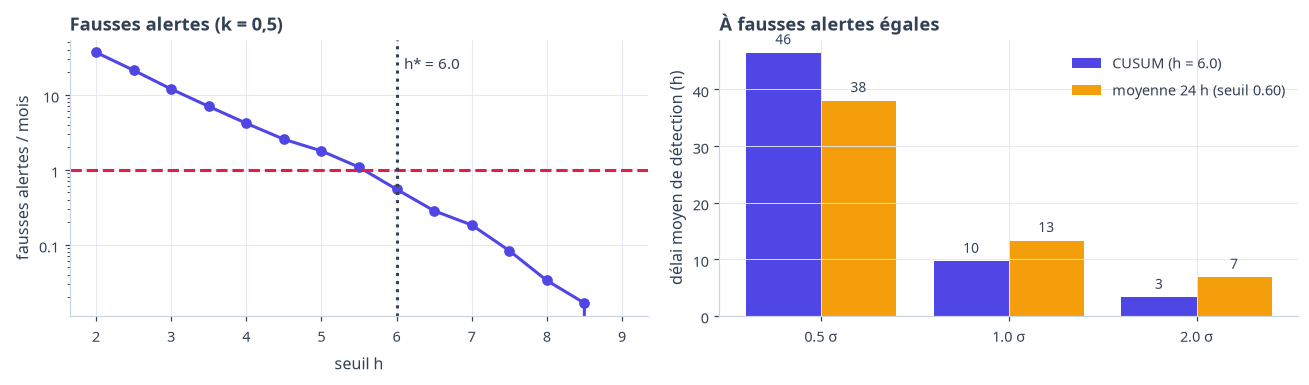

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(hs, fa, "o-", color=INDIGO); ax[0].axhline(1, color=ROSE, ls="--")
ax[0].axvline(h_star, color=SLATE, ls=":"); ax[0].text(h_star + 0.1, fa.max() * 0.6, f"h* = {h_star}", fontsize=10)
ax[0].set(yscale="log", xlabel="seuil h", ylabel="fausses alertes / mois", title="Fausses alertes (k = 0,5)")
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}")); ax[0].yaxis.set_minor_formatter(plt.NullFormatter())
x = np.arange(3)
ax[1].bar(x - 0.2, tab["CUSUM simulé (h)"], 0.4, color=INDIGO, label=f"CUSUM (h = {h_star})")
ax[1].bar(x + 0.2, tab["moyenne glissante 24 h (h)"], 0.4, color=AMBER, label=f"moyenne 24 h (seuil {thr_star:.2f})")
annotate_bars(ax[1], "{:.0f}")
ax[1].set_xticks(x, [f"{d} σ" for d in deltas]); ax[1].set(ylabel="délai moyen de détection (h)", title="À fausses alertes égales")
ax[1].legend(); plt.tight_layout(); plt.show()

L'approximation donne le bon ordre de grandeur et la bonne tendance ; elle surestime un peu
le délai simulé, car au moment du saut le CUSUM est souvent déjà au-dessus de zéro (petite
« avance » accumulée par le bruit). Pour $\delta = k$ la détection est lente, comme prévu.
À taux de fausses alertes égal, le CUSUM détecte plus vite qu'une moyenne glissante pour
les sauts nets ($1\sigma$, $2\sigma$), car la moyenne « attend » que sa fenêtre se remplisse
de valeurs décalées ; pour le petit saut ($0{,}5\sigma$), la moyenne glissante fait aussi
bien voire mieux. Un CUSUM est optimisé pour une taille de saut : on choisit
$k \approx \delta/2$ pour le saut que l'on veut détecter.

> **À retenir.** Le seuil $h$ se règle sur un budget de fausses alertes ; le délai vaut
> alors environ $h/(\delta - k)$ heures (approximation de Siegmund pour plus de précision),
> ce qui fixe le MTTD atteignable.

## Exercice 10.9 : Chemin critique et placement d'un garde-fou lent

**Énoncé.** Un pipeline comprend : masquage PII (5 ms), routage (15 ms, ne dépend que de la
requête), recherche du cache (20 ms, après masquage), recherche documentaire (40 ms, après
masquage), reclassement (60 ms, après recherche), génération (900 ms, après reclassement et
routage), garde-fou de sortie (30 ms). On veut ajouter un **détecteur d'injection
neuronal** de 300 ms. (1) Calculer la latence séquentielle et la latence parallèle (chemin
critique) du pipeline de base. (2) Comparer deux placements du détecteur : (a) en série avant
la recherche ; (b) en parallèle de la recherche et de la génération, la génération étant
**annulée** si le détecteur bloque (2 % des requêtes). Donner la latence et le gaspillage de
calcul de chaque option. Vérifier avec `A.Pipeline`.

**Rappels.** Section *AI Pipeline Orchestration* : paralléliser autant que possible quand la
latence compte (par exemple routage et retrait des PII). Cours 3 : la latence d'un graphe est
celle de son chemin critique.

**Solution.** (1) Séquentiel : $5 + 15 + 20 + 40 + 60 + 900 + 30 = 1\,070$ ms. En parallèle,
le chemin critique est PII -> recherche -> reclassement -> génération -> garde-fou :
$5 + 40 + 60 + 900 + 30 = 1\,035$ ms (le routage et le cache sont « gratuits »).

(2a) En série, le détecteur s'ajoute au chemin critique : $1\,335$ ms (+29 %). Aucun calcul
gaspillé (les requêtes bloquées s'arrêtent après 305 ms).

(2b) En parallèle, il part avec la recherche après le masquage ; il finit à $5 + 300 = 305$ ms,
bien avant la génération ($5 + 40 + 60 + 900 = 1\,005$ ms) : la latence reste $1\,035$ ms.
Pour les 2 % de requêtes bloquées, la génération est annulée à 305 ms, après
$305 - 105 = 200$ ms de génération inutile : gaspillage moyen $0{,}02 \times 200 = 4$ ms de
GPU par requête, négligeable devant les 300 ms de latence économisées.

In [8]:
def build(placement):
    p = (A.Pipeline(placement)
         .add("pii", lambda q: q, ["query"], "masked", 5)
         .add("routage", lambda q: "x", ["query"], "intent", 15)
         .add("cache", lambda m: None, ["masked"], "cached", 20))
    if placement == "série":
        p.add("injection", lambda m: m, ["masked"], "checked", 300)
        p.add("recherche", lambda m: [], ["checked"], "docs", 40)
    else:
        p.add("recherche", lambda m: [], ["masked"], "docs", 40)
    p.add("reclassement", lambda d: d, ["docs"], "ranked", 60)
    p.add("generation", lambda r, i: "...", ["ranked", "intent"], "draft", 900)
    p.add("garde_sortie", lambda d: d, ["draft"], "answer", 30)
    if placement == "parallèle":
        p.add("injection", lambda m: True, ["masked"], "verdict", 300)
    return p

rows = []
for name, p in [("sans détecteur", build("base")), ("détecteur en série", build("série")),
                ("détecteur en parallèle", build("parallèle"))]:
    lat = p.latency(); p.run(query="test")
    rows.append({"pipeline": name, "séquentiel (ms)": lat["sequentielle"], "parallèle (ms)": lat["parallele"],
                 "chemin critique": " -> ".join(lat["chemin_critique"])})
pd.DataFrame(rows)

,pipeline,séquentiel (ms),parallèle (ms),chemin critique
0,sans détecteur,1070,1035.0,pii -> recherche -> reclassement -> generation -> garde_sortie
1,détecteur en série,1370,1335.0,pii -> injection -> recherche -> reclassement -> generation -> garde_sortie
2,détecteur en parallèle,1370,1035.0,pii -> recherche -> reclassement -> generation -> garde_sortie


**Vérification** par un diagramme de Gantt de l'ordonnancement parallèle (début au plus tôt
de chaque étape).

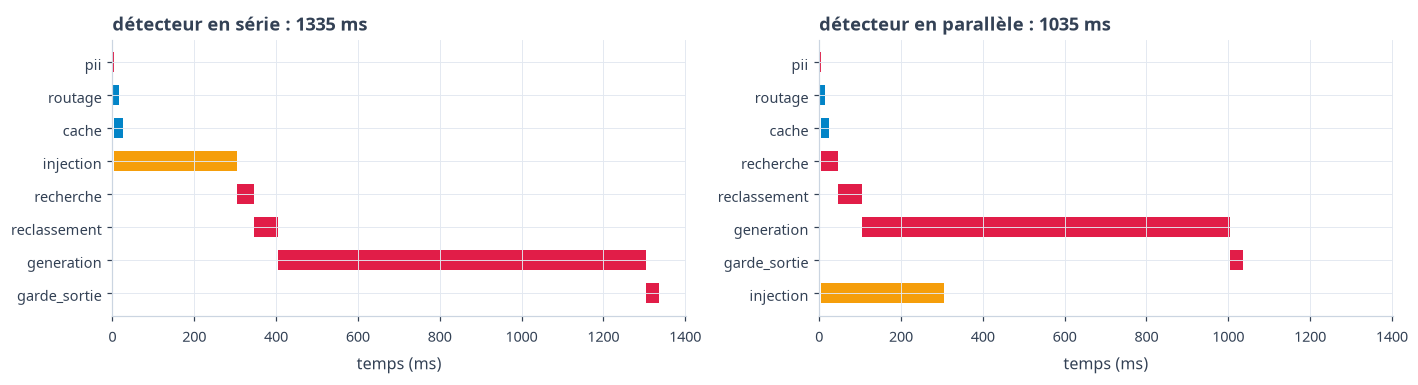

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharex=True)
for ax, (name, p) in zip(axes, [("détecteur en série", build("série")), ("détecteur en parallèle", build("parallèle"))]):
    lat = p.latency(); g = p.graph()
    order = list(p.steps)
    for i, n in enumerate(order):
        start = lat["fin"][n] - p.steps[n].latency_ms
        col = ROSE if n in lat["chemin_critique"] else SKY
        if n == "injection":
            col = AMBER
        ax.barh(i, p.steps[n].latency_ms, left=start, color=col, height=0.6)
    ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
    ax.set(xlabel="temps (ms)", title=f"{name} : {lat['parallele']:.0f} ms")
plt.tight_layout(); plt.show()

> **À retenir.** Un composant lent hors du chemin critique ne coûte presque rien en
> latence ; l'exécution spéculative (lancer la génération et l'annuler si le garde-fou
> bloque) échange un peu de calcul gaspillé contre beaucoup de latence.

## Exercice 10.10 : Apprendre un score de satisfaction implicite

**Énoncé.** Le cours 4 combine les signaux conversationnels avec des poids choisis à la
main. (1) Construire un générateur de conversations synthétiques réaliste (comptes de
signaux selon que l'utilisateur est satisfait ou non). (2) Apprendre les poids par
**régression logistique** et tracer l'AUC sur des données de test en fonction du nombre de
conversations annotées. (3) Comparer les poids appris aux poids manuels, puis appliquer les
deux scores aux 12 conversations réelles de `A.CONVERSATIONS`.

**Rappels.** Section *Extracting Conversational Feedback* : l'intuition propose des signaux,
mais « une analyse rigoureuse des données » est nécessaire pour les interpréter. Cours 4 :
`A.extract_signals`, `A.implicit_score`, `A.SIGNAL_WEIGHTS`.

**Solution.** Modèle génératif : chaque signal de comptage suit une loi de Poisson dont le
taux dépend de la satisfaction (par exemple 0,1 reformulation par conversation satisfaite
contre 0,8 pour une insatisfaite) ; le sentiment final est gaussien, centré sur +0,5 ou
-0,4 et tronqué à $[-1, 1]$. La régression logistique modélise
$P(\text{satisfait} \mid x) = \sigma(w^\top x + b)$ ; ses poids sont directement
interprétables comme des contributions au log-rapport de cotes.

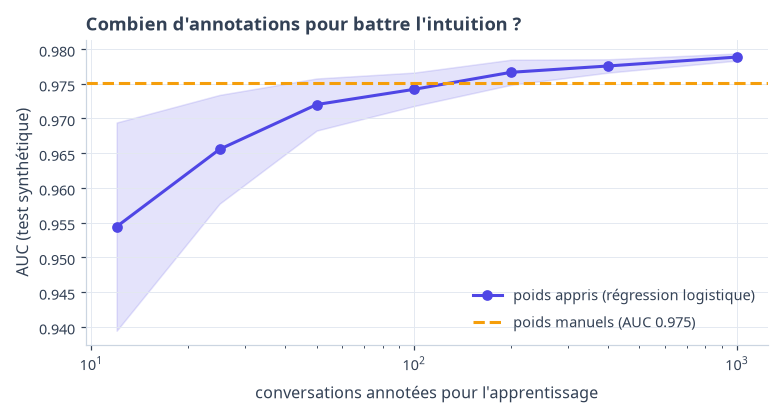

In [10]:
FEATS = ["reformulations", "corrections", "demandes_confirmation", "plaintes", "interruptions", "regenerations",
         "refus_modele", "sentiment_final", "sentiment_moyen"]
RATES = {  # (satisfait, insatisfait)
    "reformulations": (0.10, 0.80), "corrections": (0.20, 0.60), "demandes_confirmation": (0.25, 0.35),
    "plaintes": (0.10, 0.90), "interruptions": (0.05, 0.70), "regenerations": (0.10, 0.40), "refus_modele": (0.05, 0.50)}

def synth(n, seed=0, p_sat=0.65):
    r = np.random.default_rng(seed)
    y = (r.random(n) < p_sat).astype(int)
    X = {f: r.poisson(np.where(y == 1, a, b)) for f, (a, b) in RATES.items()}
    X["sentiment_final"] = np.clip(r.normal(np.where(y == 1, 0.5, -0.4), 0.6), -1, 1)
    X["sentiment_moyen"] = np.clip(0.5 * X["sentiment_final"] + r.normal(0, 0.3, n), -1, 1)
    return pd.DataFrame(X)[FEATS], y

X_test, y_test = synth(4000, seed=99)
manual = np.array([A.SIGNAL_WEIGHTS[f] for f in FEATS])
auc_manual = roc_auc_score(y_test, X_test.values @ manual)
sizes = [12, 25, 50, 100, 200, 400, 1000]
aucs = []
for n in sizes:
    a = []
    for s in range(20):
        X, y = synth(n, seed=s)
        if len(set(y)) < 2:
            continue
        m = LogisticRegression(C=1.0, max_iter=1000).fit(X, y)
        a.append(roc_auc_score(y_test, m.decision_function(X_test)))
    aucs.append((np.mean(a), np.std(a)))
aucs = np.array(aucs)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(sizes, aucs[:, 0], "o-", color=INDIGO, label="poids appris (régression logistique)")
ax.fill_between(sizes, aucs[:, 0] - aucs[:, 1], aucs[:, 0] + aucs[:, 1], color=INDIGO, alpha=0.15)
ax.axhline(auc_manual, color=AMBER, ls="--", label=f"poids manuels (AUC {auc_manual:.3f})")
ax.set(xscale="log", xlabel="conversations annotées pour l'apprentissage", ylabel="AUC (test synthétique)",
       title="Combien d'annotations pour battre l'intuition ?")
ax.legend(); plt.show()

**Vérification** : poids appris contre poids manuels, puis application aux 12 conversations
réelles.

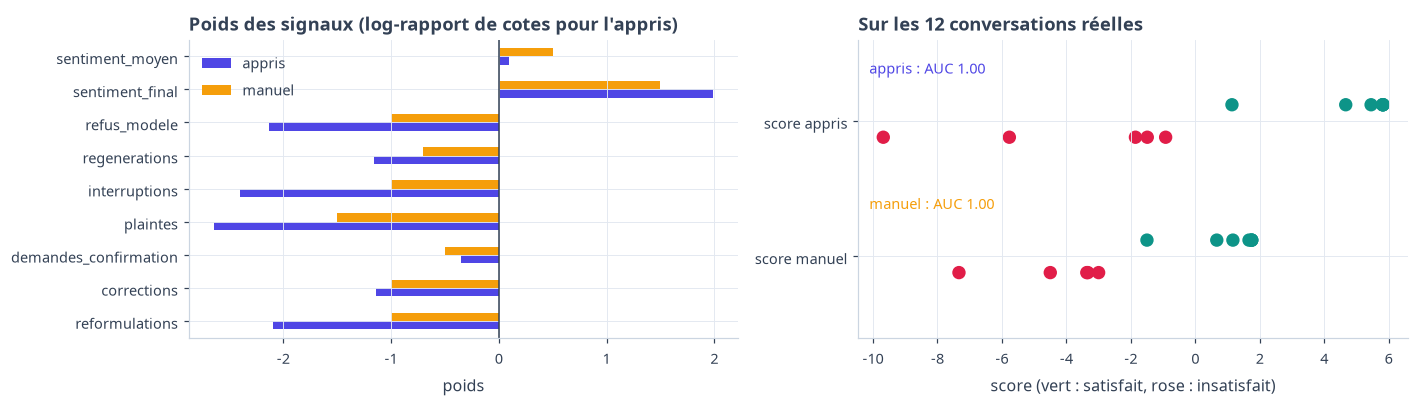

In [11]:
X, y = synth(1000, seed=0)
m = LogisticRegression(C=1.0, max_iter=1000).fit(X, y)
w = pd.DataFrame({"appris": m.coef_[0], "manuel": manual}, index=FEATS)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
w.plot.barh(ax=ax[0], color=[INDIGO, AMBER]); ax[0].axvline(0, color=SLATE, lw=1)
ax[0].set(title="Poids des signaux (log-rapport de cotes pour l'appris)", xlabel="poids")
real = pd.DataFrame([A.extract_signals(c) for c, _ in A.CONVERSATIONS])[FEATS]
y_real = np.array([l for _, l in A.CONVERSATIONS])
s_learn, s_man = m.decision_function(real), real.values @ manual
for k, (s, name, col) in enumerate([(s_man, "manuel", AMBER), (s_learn, "appris", INDIGO)]):
    ax[1].scatter(s, np.full(len(s), k) + np.where(y_real == 1, 0.12, -0.12), c=[TEAL if v else ROSE for v in y_real], s=60)
    ax[1].text(0.02, (k + 0.95) / 2.2, f"{name} : AUC {roc_auc_score(y_real, s):.2f}", fontsize=9.5, color=col,
               transform=ax[1].transAxes)
ax[1].set_yticks([0, 1], ["score manuel", "score appris"])
ax[1].set(xlabel="score (vert : satisfait, rose : insatisfait)", title="Sur les 12 conversations réelles", ylim=(-0.6, 1.6))
plt.tight_layout(); plt.show()

Avec une douzaine d'annotations, les poids appris sont instables et font moins bien que
l'intuition ; il faut ici de l'ordre de 150 à 200 conversations annotées pour la dépasser
(nos poids manuels sont déjà bons, car proches du générateur). Les poids appris retrouvent l'ordre d'importance du générateur (interruptions,
plaintes, reformulations et sentiment final dominent ; les demandes de confirmation, presque
aussi fréquentes chez les satisfaits, pèsent peu). Attention : le générateur est le nôtre,
donc le modèle appris est jugé « chez lui ». Sur les vraies conversations, il faut annoter
des données réelles : c'est la seule façon de savoir ce que signifient les signaux **pour vos
utilisateurs**.

> **À retenir.** Un score implicite se calibre sur des conversations annotées ; quelques
> centaines d'exemples suffisent à dépasser des poids intuitifs et à révéler les signaux
> réellement informatifs.

## Exercice 10.11 : Biais de position, puissance statistique et boucle de rétroaction

**Énoncé.** Des utilisateurs comparent deux réponses A et B affichées dans un ordre
**aléatoire** ; une fraction $\pi$ clique toujours sur la première. (1) Montrer que le taux de
victoire observé de A vaut $\tfrac{1}{2} + (1-\pi)(q - \tfrac{1}{2})$ où $q$ est la vraie
préférence. (2) En déduire comment le nombre de comparaisons nécessaires pour détecter
$q = 0{,}55$ (test unilatéral à 5 %, puissance 80 %) dépend de $\pi$ ; vérifier par
simulation. (3) Dans la boucle de recommandation du cours 4, faire varier l'exploration
$\varepsilon$ et comparer la probabilité de converger vers le meilleur élément et le nombre
total de clics, avec et sans correction IPW.

**Rappels.** Section *Biases* (position bias : randomiser les positions ou modéliser leur
effet) et *Degenerate feedback loop*. Cours 4 : `A.simulate_position_bias`,
`A.simulate_feedback_loop`.

**Solution.** (1) A est en premier avec probabilité 1/2. Un utilisateur « paresseux »
(probabilité $\pi$) choisit A si A est en premier : contribution $\pi/2$. Un utilisateur
attentif choisit A avec probabilité $q$ : contribution $(1-\pi)q$. Total
$\pi/2 + (1-\pi) q = \tfrac12 + (1-\pi)(q - \tfrac12)$. $\blacksquare$

(2) L'écart à 1/2 est multiplié par $(1-\pi)$. Pour un test de proportion, le nombre de
comparaisons nécessaires est $n \approx \left(\frac{z_{0{,}95} + z_{0{,}80}}{\Delta}\right)^2 \cdot
\tfrac14$ avec $\Delta$ l'écart à 1/2 ; donc
$$n(\pi) = \frac{n(0)}{(1-\pi)^2}, \qquad n(0) = \frac{(1{,}645 + 0{,}842)^2}{4 \times 0{,}05^2} \approx 619.$$
Avec $\pi = 0{,}5$, il faut 4 fois plus de comparaisons (environ 2 474) : le biais de position
ne fausse pas l'estimation randomisée, mais il **gaspille** des retours.

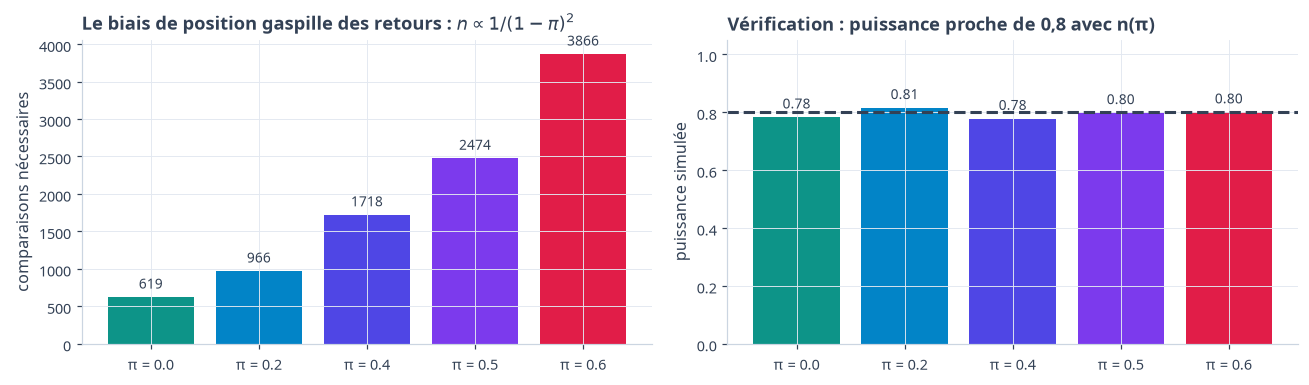

In [12]:
z = 1.645 + 0.842
pis = np.array([0.0, 0.2, 0.4, 0.5, 0.6])
n_theo = (z / (0.05 * (1 - pis))) ** 2 / 4

def power(n, pi, q=0.55, reps=400, seed=0):
    r = np.random.default_rng(seed)
    a_first = r.random((reps, n)) < 0.5
    lazy = r.random((reps, n)) < pi
    choose = np.where(lazy, a_first, r.random((reps, n)) < q)
    phat = choose.mean(1)
    return np.mean((phat - 0.5) / np.sqrt(0.25 / n) > 1.645)

pw = [power(int(n), pi) for n, pi in zip(n_theo, pis)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar([f"π = {p}" for p in pis], n_theo, color=[TEAL, SKY, INDIGO, VIOLET, ROSE]); annotate_bars(ax[0], "{:.0f}")
ax[0].set(ylabel="comparaisons nécessaires", title="Le biais de position gaspille des retours : $n \\propto 1/(1-\\pi)^2$")
ax[1].bar([f"π = {p}" for p in pis], pw, color=[TEAL, SKY, INDIGO, VIOLET, ROSE]); annotate_bars(ax[1], "{:.2f}")
ax[1].axhline(0.8, color=SLATE, ls="--"); ax[1].set(ylabel="puissance simulée", ylim=(0, 1.05),
                                                     title="Vérification : puissance proche de 0,8 avec n(π)")
plt.tight_layout(); plt.show()

(3) **Boucle de rétroaction.** On reprend 5 éléments de qualités proches et on fait varier
$\varepsilon$, sur 20 graines.

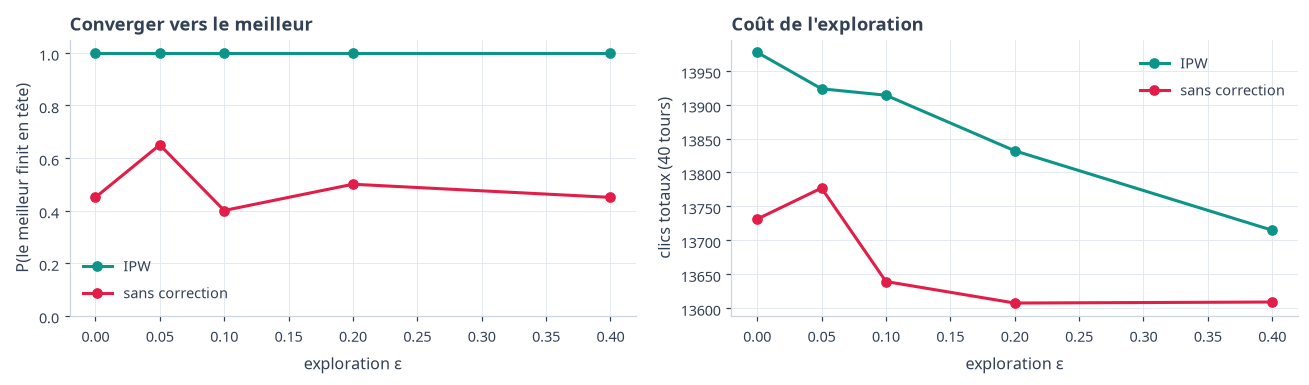

,politique,ε,P(meilleur en tête),clics totaux
0,sans correction,0.00,0.45,13731.20
1,sans correction,0.05,0.65,13777.00
2,sans correction,0.10,0.40,13639.10
3,sans correction,0.20,0.50,13607.35
4,sans correction,0.40,0.45,13608.85
5,IPW,0.00,1.00,13977.30
6,IPW,0.05,1.00,13923.45
7,IPW,0.10,1.00,13914.00
8,IPW,0.20,1.00,13832.05
9,IPW,0.40,1.00,13714.75


In [13]:
quals = [0.30, 0.33, 0.27, 0.31, 0.25]
eps_grid = [0.0, 0.05, 0.1, 0.2, 0.4]
rows = []
for corr in ["epsilon", "ipw"]:
    for eps in eps_grid:
        best, clicks = [], []
        for s in range(20):
            r = A.simulate_feedback_loop(quals, n_rounds=40, policy=corr, eps=eps, seed=s)
            best.append(r["top_share"][-5:].mean(0).argmax() == 1); clicks.append(r["clicks"].sum())
        rows.append({"politique": "IPW" if corr == "ipw" else "sans correction", "ε": eps,
                     "P(meilleur en tête)": np.mean(best), "clics totaux": np.mean(clicks)})
loop = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for (name, g), col in zip(loop.groupby("politique"), [TEAL, ROSE]):
    ax[0].plot(g["ε"], g["P(meilleur en tête)"], "o-", color=col, label=name)
    ax[1].plot(g["ε"], g["clics totaux"], "o-", color=col, label=name)
ax[0].set(xlabel="exploration ε", ylabel="P(le meilleur finit en tête)", title="Converger vers le meilleur", ylim=(0, 1.05))
ax[1].set(xlabel="exploration ε", ylabel="clics totaux (40 tours)", title="Coût de l'exploration")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()
loop.round(3)

Sans correction, l'exploration ne change pas grand-chose (le meilleur élément finit en tête
dans 40 à 65 % des cas selon $\varepsilon$, au bruit près) : tant que l'estimation confond
qualité et position, l'élément installé en tête garde son avantage.
La correction IPW converge presque toujours vers le meilleur élément, même sans
exploration : dans notre simulation, tous les éléments restent affichés (à une position
connue), donc chacun reçoit des retours que l'on sait « redresser ». Si seuls les premiers
éléments étaient montrés, l'exploration redeviendrait nécessaire. L'exploration a enfin un coût : chaque affichage aléatoire met en tête
un élément moins bon, ce qui réduit légèrement les clics totaux.

> **À retenir.** Randomiser les positions rend l'estimation honnête mais multiplie les
> retours nécessaires par $1/(1-\pi)^2$ ; contre les boucles dégénérées, corriger le biais
> d'exposition (IPW) est plus efficace qu'explorer à l'aveugle.

In [14]:
llm.free_gpu()